<a href="https://colab.research.google.com/github/DhaiHamoud/Fraud-Detection-in-the-Financial-Transaction-Market/blob/main/notebooks/02_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import gdown, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, numpy as np
gdown.download(id='1VV0JLvtGmc88sN0zx8AxctvA4C-VClCs', output='clean.parquet', quiet=False)
df = pd.read_parquet('clean.parquet')

Downloading...
From (original): https://drive.google.com/uc?id=1VV0JLvtGmc88sN0zx8AxctvA4C-VClCs
From (redirected): https://drive.google.com/uc?id=1VV0JLvtGmc88sN0zx8AxctvA4C-VClCs&confirm=t&uuid=ff7cbeb3-9448-4e60-8d59-d7eb488498bb
To: /content/clean.parquet
100%|██████████| 139M/139M [00:01<00:00, 79.1MB/s]


## 1. Target Distribution — **Turki**

In [13]:
df["is_fraud"].value_counts()

,count
is_fraud,
0,1842743
1,9651


Number of legitimate transactions are 1,842,743 , and the fraud ones are 9651.

In [14]:
df["is_fraud"].value_counts(normalize=True) * 100

,proportion
is_fraud,
0,99.478999
1,0.521001


99.48% of the transactions are legitimate, and the fraud transcations are 0.52%

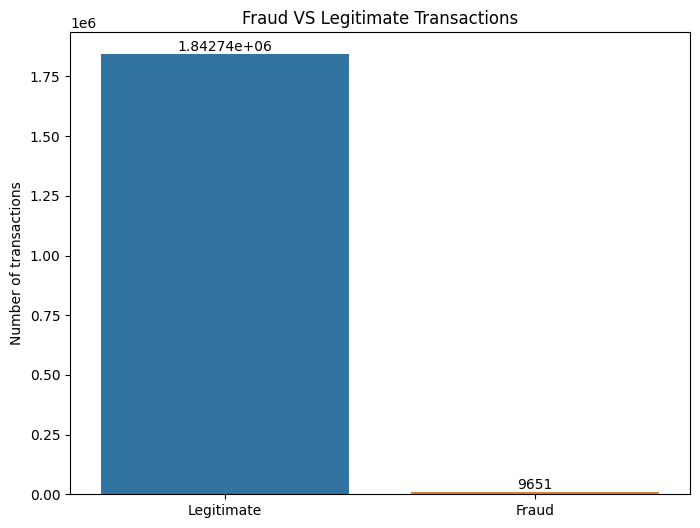

In [15]:
plt.figure(figsize=(8,6))
fig = sns.countplot(df, x="is_fraud",hue="is_fraud", legend=False);
plt.title("Fraud VS Legitimate Transactions")
fig.set_xticks([0, 1])
fig.set_xticklabels(["Legitimate", "Fraud"])
plt.ylabel("Number of transactions")
for c in fig.containers:
    fig.bar_label(c)
plt.xlabel("");

**Observation:** The dataset is highly imbalanced. Legitimate transactions are far more common than fraud, so the fraud bar is barely visible.

**Fraud is 0.52% of all transactions** (9,651 out of 1,852,394), while legitimate transactions are 99.48%. The fraud bar is barely visible because the data is highly imbalanced.

**Effect on accuracy:** Accuracy is not a reliable metric here. A model that always predicts "legitimate" would score about 99.5% accuracy while catching no fraud at all.

## 2. Amount Distribution — Abdulmohsen

In [16]:
#Summary statistics for transaction amounts
df['amt'].describe()

,amt
count,1.852394e+06
mean,7.006357e+01
std,1.592540e+02
min,1.000000e+00
25%,9.640000e+00
50%,4.745000e+01
75%,8.310000e+01
max,2.894890e+04


**Summary:** Transaction amounts range from \$1.00 to \$28,948.90. The middle 50% fall between \$9.64 and \$83.10, with a median of \$47.45 and a mean of \$70.06.

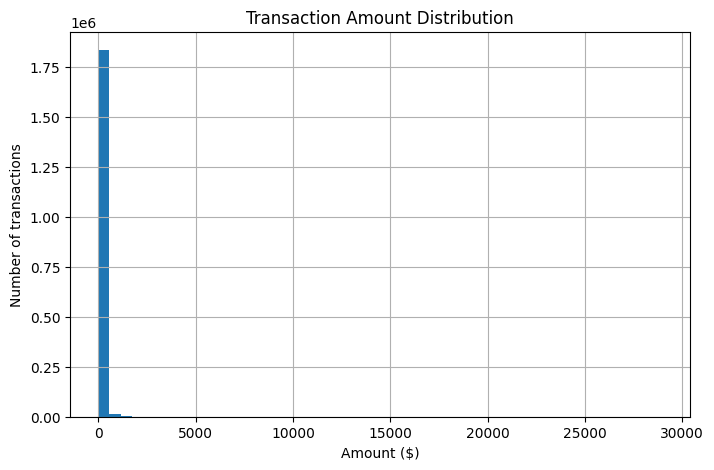

In [17]:
#Plot the distribution of transaction amounts
plt.figure(figsize=(8, 5))
df['amt'].hist(bins=50)
plt.title('Transaction Amount Distribution')
plt.xlabel('Amount ($)')
plt.ylabel('Number of transactions')
plt.show()

**Observation:** Transaction amounts are strongly right-skewed: 75% are at or below \$83.10, while the maximum reaches \$28,948.90. The mean (\$70.06) is higher than the median (\$47.45), reflecting the influence of large amounts.

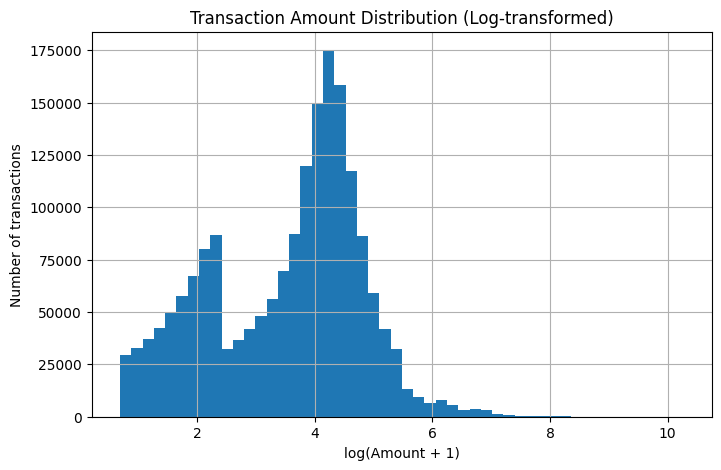

In [21]:
#Plot amounts after a log transformation
plt.figure(figsize=(8, 5))
np.log1p(df['amt']).hist(bins=50)
plt.title('Transaction Amount Distribution (Log-transformed)')
plt.xlabel('log(Amount + 1)')
plt.ylabel('Number of transactions')
plt.show()

**Observation:** The log transformation makes the distribution clearer, revealing a main peak around log(Amount + 1) = 4.2 and a smaller peak near 2.3. Large amounts remain in the right tail, but no longer compress the smaller amounts into a single dominant bar.

**Unexpected:** The log-transformed histogram reveals two distinct peaks that were not visible on the original scale; the reason for this pattern needs further investigation.